Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  ...   Chest Pain Type  Heart Disease
0   75  Female  ...   Atypical Angina              1
1   48    Male  ...    Typical Angina              0
2   53    Male  ...   Atypical Angina              1
3   69  Female  ...  Non-anginal Pain              0
4   62  Female  ...      Asymptomatic              0

[5 rows x 16 columns]

Cluster Labels:
Cluster
-1    1000
Name: count, dtype: int64

Number of Noise Points:
1000

Noise Points:
   Age  Gender  Cholesterol  ...   Chest Pain Type  Heart Disease Cluster
0   75  Female          228  ...   Atypical Angina              1      -1
1   48    Male          204  ...    Typical Angina              0      -1
2   53    Male          234  ...   Atypical Angina              1      -1
3   69  Female          192  ...  Non-anginal Pain              0      -1
4   62  Female          172  ...      Asymptomatic              0      -1
5   77    Male          309  ...      Asymptomatic              

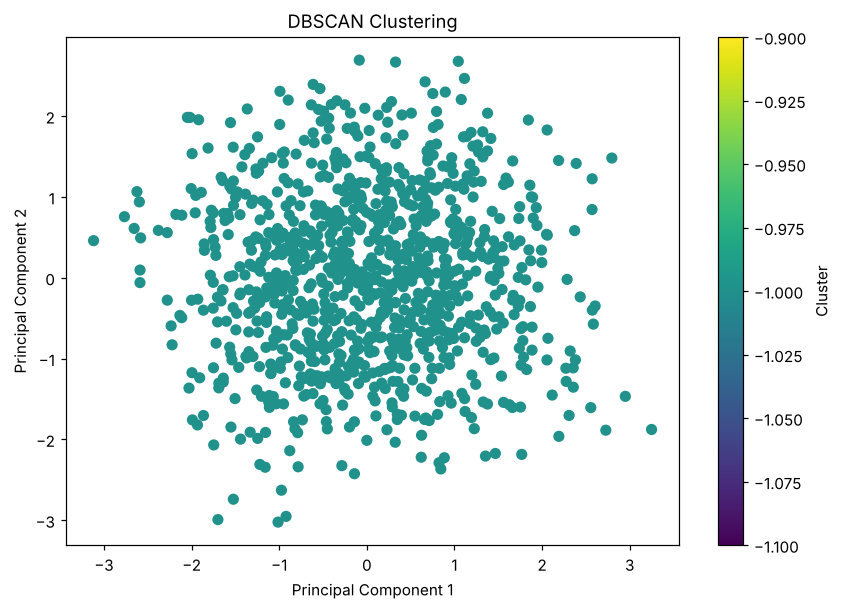

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA

df = pd.read_csv("heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)

X_processed = X_processed

dbscan = DBSCAN(
    eps=1.5,
    min_samples=5
)

labels = dbscan.fit_predict(X_processed)

df["Cluster"] = labels

print("\nCluster Labels:")
print(df["Cluster"].value_counts().sort_index())

noise_points = df[df["Cluster"] == -1]

print("\nNumber of Noise Points:")
print(len(noise_points))

print("\nNoise Points:")
print(noise_points.head(10))

number_of_clusters = len(
    set(labels)
) - (1 if -1 in labels else 0)

print("\nNumber of Clusters:")
print(number_of_clusters)

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_processed)

plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("DBSCAN Clustering")

plt.colorbar(label="Cluster")

plt.show()
